In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import torch
from torch.utils.data import Dataset
from matplotlib import pyplot as plt
from torch.utils.data import DataLoader

In [11]:

def load_binary_mask(path):
        with rasterio.open(path ) as src:
            mask = src.read(1)
        mask = (mask == 0 )
        return mask

def load_tif(path):
        with rasterio.open(path) as src:
            array = src.read()
        return array

class LidarDataset(Dataset):
    def __init__(self, manifest_csv, split, representation = 'combined', augment = False):
        self.manifest = pd.read_csv(manifest_csv)
        self.manifest = self.manifest[self.manifest['split'] == split].reset_index(drop=True)
        self.representation = representation
        self.augment = augment

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        row = self.manifest.iloc[idx]
        image = load_tif(Path(row['lidar_path']))
        building = load_binary_mask(Path(row['building_mask']))
        platform = load_binary_mask(Path(row['platform_mask']))
        aguada = load_binary_mask(Path(row['aguada_mask']))
        if self.representation == 'svf':
            image = image[0:1]
        elif self.representation == 'openness':
            image = image[1:2]
        elif self.representation == 'slope':
            image = image[2:3]
        elif self.representation == 'combined':
            image = image
        else:
            raise ValueError(f"Unknown representation: {self.representation}")
        masks = np.stack([building, platform, aguada], axis=0).astype(np.float32)
        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(image)
        mask = masks.astype(np.float32)
        mask = torch.from_numpy(mask)
        if self.augment:
            if torch.rand(1).item() > 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[2])
            if torch.rand(1).item() > 0.5:
                image = torch.flip(image, dims=[1])
                mask = torch.flip(mask, dims=[1])
            k = torch.randint(0, 4, (1,)).item()
            image = torch.rot90(image, k, dims=[1, 2])
            mask = torch.rot90(mask, k, dims=[1, 2])
        return image, mask
    





In [12]:
manifest_path = Path('../data/processed/manifest_split.csv')
train_dataset = LidarDataset(manifest_path, split='train', representation='combined', augment=True)
test_dataset = LidarDataset(manifest_path, split='test', representation='combined', augment=False)
val_dataset = LidarDataset(manifest_path, split='val', representation='combined', augment=False)
print(f"Train dataset length: {len(train_dataset)}")
print(f"Test dataset length: {len(test_dataset)}")
print(f"Validation dataset length: {len(val_dataset)}")


Train dataset length: 1465
Test dataset length: 315
Validation dataset length: 314


In [13]:
image, mask = train_dataset[0]
print(f"Image shape: {image.shape}")
print(f"Mask shape: {mask.shape}")
print(f"Image dtype: {image.dtype}")
print(f"Mask dtype: {mask.dtype}")
print(f"Unique values in mask: {torch.unique(mask)}")

Image shape: torch.Size([3, 480, 480])
Mask shape: torch.Size([3, 480, 480])
Image dtype: torch.float32
Mask dtype: torch.float32
Unique values in mask: tensor([0., 1.])


/home/jacobrawlins/Lidar_Project/.venv/lib/python3.12/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [14]:
building = mask[0].bool()
platform = mask[1].bool()
aguada = mask[2].bool()
print(f'Building Pixels: {building.sum().item()}')
print(f'Platform Pixels: {platform.sum().item()}')
print(f'Aguada Pixels: {aguada.sum().item()}')
print(f'Building and Platform Overlap: {(building & platform).sum().item()}')

Building Pixels: 7620
Platform Pixels: 47877
Aguada Pixels: 0
Building and Platform Overlap: 6967


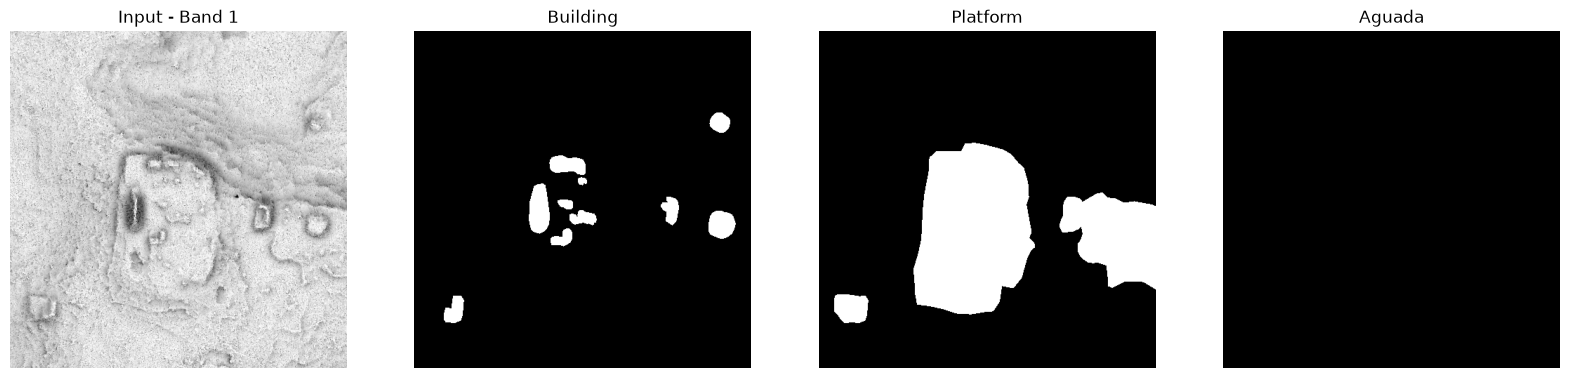

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(image[0].numpy(), cmap="gray")
axes[0].set_title("Input - Band 1")

axes[1].imshow(mask[0].numpy(), cmap="gray")
axes[1].set_title("Building")

axes[2].imshow(mask[1].numpy(), cmap="gray")
axes[2].set_title("Platform")

axes[3].imshow(mask[2].numpy(), cmap="gray")
axes[3].set_title("Aguada")

for ax in axes:
    ax.axis("off")

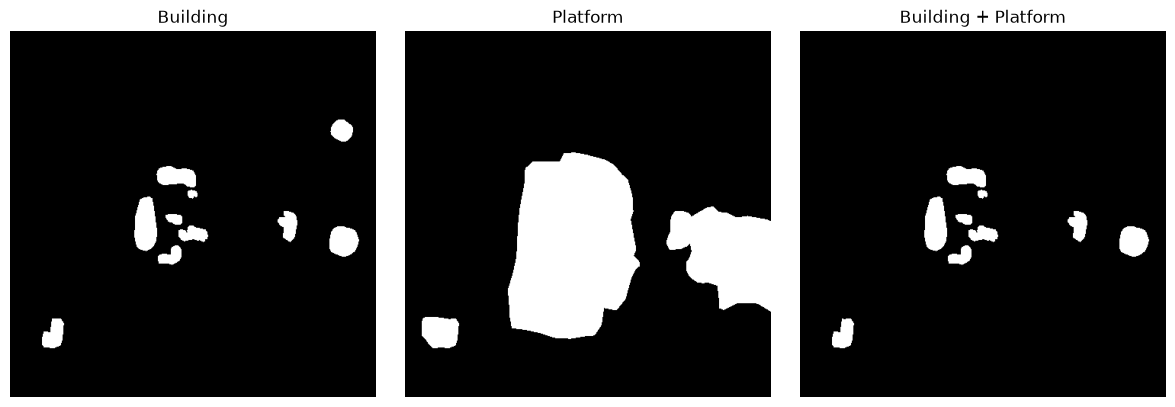

In [16]:
building = mask[0].bool()
platform = mask[1].bool()
overlap = building & platform
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(building.numpy(), cmap="gray")
axes[0].set_title("Building")

axes[1].imshow(platform.numpy(), cmap="gray")
axes[1].set_title("Platform")

axes[2].imshow(overlap.numpy(), cmap="gray")
axes[2].set_title("Building + Platform")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True)
image, masks = next(iter(train_loader))
print(f"Batch image shape: {image.shape}")
print(f"Batch masks shape: {masks.shape}")
print(f"Batch image dtype: {image.dtype}")
print(f"Batch masks dtype: {masks.dtype}")
print(f"Batch unique values in masks: {torch.unique(masks)}")

Batch image shape: torch.Size([4, 3, 480, 480])
Batch masks shape: torch.Size([4, 3, 480, 480])
Batch image dtype: torch.float32
Batch masks dtype: torch.float32
Batch unique values in masks: tensor([0., 1.])
